# 16 Fallsammlung: Begehungen im Ternärbild

- Wo zeigt das Ternärbild eine Effizienzsteigerung, und fällt sie mit einer Begehung zusammen?
- Taugt der Vergleich der Stationen untereinander? Bis auf eine Schule alles Wohnhäuser
- Anschluss an Notebook 12: welche Stationen verschieben ihre Effizienz, wie verhalten sich Stationen ohne Begehung?
- Maßstab sind Effektstärken und Häufigkeiten; bei 94 Stationen und 66 Begehungen ist Signifikanz nicht zu erwarten

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import fallsammlung as fs
from src import load_begehungen as lb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
OUT_DIR = ROOT / "outputs" / "fallsammlung"
OUT_DIR.mkdir(parents=True, exist_ok=True)

t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}", flush=True)

## Gruppen bilden

- Begehungsgruppe: Stationen mit Termin in der Begehungstabelle
- Kontrollgruppe: Pseudodatum aus der Verteilung der echten Termine, gleiches Kalenderfenster
- Fünf Begehungen ohne Datum fallen aus beiden Gruppen heraus

In [2]:
serien = tn.lade_serien(METER_DIR)
termine = lb.begehung_dates_by_meter(available=set(serien))
begehungsdatum = {m: sorted(d)[0] for m, d in termine.items() if d}

beg_alle = lb.begehungen_mit_zaehler()
ohne_datum = ((set(beg_alle["meter"].dropna().astype(int))
               - set(begehungsdatum)) & set(serien))
kontrolle = fs.kontrollgruppe(serien, begehungsdatum, ausschluss=ohne_datum)

datum = {**begehungsdatum, **kontrolle}
tick(f"{len(serien)} Zaehlerreihen")
print(f"Begehungsgruppe {len(begehungsdatum)}, Kontrollgruppe {len(kontrolle)}, "
      f"ohne Datum und deshalb ausgeschlossen {len(ohne_datum)}")
print(f"ausgeschlossene Zaehler: {sorted(ohne_datum)}")

[    19s] 100 Zaehlerreihen
Begehungsgruppe 56, Kontrollgruppe 44, ohne Datum und deshalb ausgeschlossen 5
ausgeschlossene Zaehler: [65273846, 68956347, 72135481, 72167782, 80912202]


## Warum saisongleich verglichen wird

- Der Schnitt in `src/ternaer.py` teilt die ganze Historie am Begehungsdatum: zwei bis drei Jahre Vorher gegen einen Winter Nachher, weil fast alle Termine im Spätsommer und Herbst 2024 liegen
- Der Rücklauf ist im Winter systematisch anders, der naive Vergleich misst also teils die Jahreszeit

In [3]:
begangen = set(begehungsdatum)
effekt = {}
for name, saison in (("naiv", None), ("winter", tn.GRUPPE_WINTER)):
    effekt[name] = fs.effekt_je_station(serien, datum, begangen, saison=saison)
    tick(f"Schnitt {name}: {len(effekt[name])} Stationen")

vergleich = []
for name, tab in effekt.items():
    t = tab[tab["genug"]]
    for gruppe, teil in (("Begehung", t[t["begehung"]]),
                         ("Kontrolle", t[~t["begehung"]])):
        s = teil["d_perf"].dropna()
        vergleich.append({"schnitt": name, "gruppe": gruppe, "n": len(s),
                          "median": round(float(s.median()), 2),
                          "mittel": round(float(s.mean()), 2),
                          "anteil_positiv": round(float((s > 0).mean()), 2)})
print(pd.DataFrame(vergleich).to_string(index=False))

[    32s] Schnitt naiv: 95 Stationen
[    46s] Schnitt winter: 95 Stationen
schnitt    gruppe  n  median  mittel  anteil_positiv
   naiv  Begehung 43    0.00    1.51            0.49
   naiv Kontrolle 34    1.13    2.66            0.56
 winter  Begehung 41    0.81    1.49            0.59
 winter Kontrolle 31   -0.58    1.25            0.39


- Naiv liegt die Kontrollgruppe vorn (Median +1,13 gegen 0,00), im Winterschnitt dreht es sich um (−0,58 gegen +0,81)
- Alles Weitere läuft über den Winterschnitt

In [4]:
winter = effekt["winter"]
winter = winter[winter["genug"]].copy()

kodiert = bc.kodiere_begehungen()
labels = bc.labels_je_zaehler(kodiert)
winter = fs.markiere_mechanisch(winter, labels)

notiz = (beg_alle.dropna(subset=["sonstiges"]).groupby("meter")["sonstiges"]
         .apply(lambda s: " | ".join(str(x) for x in s)))
winter["notiz"] = winter["meter"].map(notiz)

winter["lage"] = np.where(~winter["begehung"], "ohne Begehung",
                          np.where(winter["mechanisch"],
                                   "Begehung, mechanisch",
                                   "Begehung, kein mechanischer Befund"))
print(winter["lage"].value_counts().to_string())

lage
ohne Begehung                         31
Begehung, kein mechanischer Befund    27
Begehung, mechanisch                  14


## Wirkung je Gruppe

- Mechanisch: Freitext nennt Schmutzfänger, Ventil oder Stellantrieb, Pumpe, Zirkulation oder Volumenstrom (Notebook 15); nur ein solcher Eingriff verschiebt Leistung zu Durchfluss
- Effektstärke Cliffs Delta: wie oft ein Wert der einen Gruppe größer ist als einer der anderen

In [5]:
print("Aenderung der Performance im Winter, in kWh/m3")
print(fs.gruppenvergleich(winter, "lage").round(2).to_string(index=False))
print()

mech = winter[winter["lage"] == "Begehung, mechanisch"]["d_perf"].dropna()
nmech = winter[winter["lage"] == "Begehung, kein mechanischer Befund"]["d_perf"].dropna()
kon = winter[winter["lage"] == "ohne Begehung"]["d_perf"].dropna()

for name, x, y in (("mechanisch gegen nicht mechanisch", mech, nmech),
                   ("mechanisch gegen Kontrolle", mech, kon),
                   ("nicht mechanisch gegen Kontrolle", nmech, kon)):
    d = fs.cliffs_delta(x, y)
    p = stats.mannwhitneyu(x, y, alternative="two-sided").pvalue
    print(f"{name:36s} Cliffs delta {d:+.3f}   (p = {p:.3f})")

Aenderung der Performance im Winter, in kWh/m3
                            gruppe  n  median  mittel  anteil_positiv
Begehung, kein mechanischer Befund 27    0.29   -0.72            0.52
              Begehung, mechanisch 14    1.98    5.76            0.71
                     ohne Begehung 31   -0.58    1.25            0.39

mechanisch gegen nicht mechanisch    Cliffs delta +0.386   (p = 0.046)
mechanisch gegen Kontrolle           Cliffs delta +0.267   (p = 0.159)
nicht mechanisch gegen Kontrolle     Cliffs delta -0.060   (p = 0.703)


- Reihenfolge wie erwartet: mechanisch (Median +1,98) vor Begehung ohne mechanischen Befund (+0,29) vor keiner Begehung (−0,58)
- Zwischen den Begehungsgruppen Cliffs Delta rund 0,39 (p = 0,046) bei 14 gegen 27 Stationen: Muster, kein Beweis. Übrige Vergleiche klar über 0,05
- Ohne Begehung verschlechtert sich die Mehrheit leicht

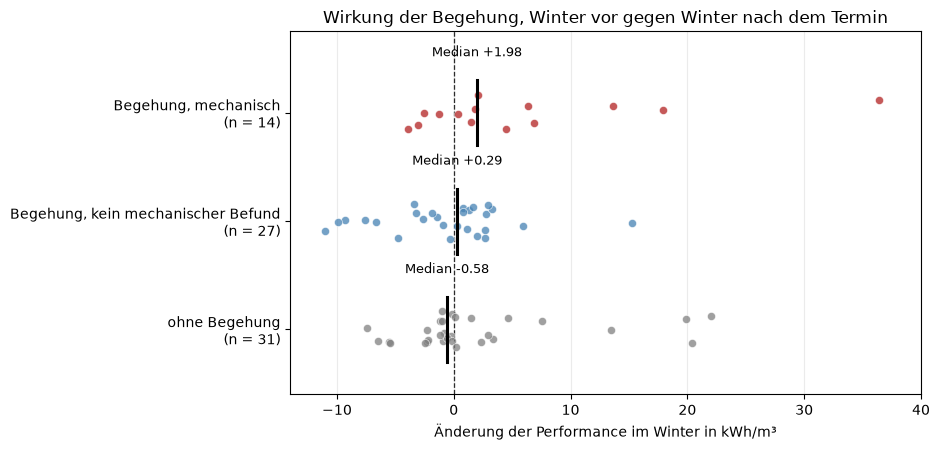

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
reihen = ["Begehung, mechanisch", "Begehung, kein mechanischer Befund",
          "ohne Begehung"]
farben = ["firebrick", "steelblue", "grey"]
rng = np.random.default_rng(1)
for i, (name, farbe) in enumerate(zip(reihen, farben)):
    s = winter[winter["lage"] == name]["d_perf"].dropna()
    y = i + rng.uniform(-0.17, 0.17, len(s))
    ax.scatter(s, y, s=34, color=farbe, alpha=0.75, edgecolor="white",
               linewidth=0.5, zorder=3)
    ax.plot([s.median(), s.median()], [i - 0.3, i + 0.3], color="black",
            lw=2.2, zorder=4)
    ax.text(s.median(), i - 0.52, f"Median {s.median():+.2f}", ha="center",
            fontsize=9)
ax.axvline(0, color="black", lw=0.9, ls="--", zorder=1)
ax.set_yticks(range(len(reihen)))
ax.set_yticklabels([f"{n}\n(n = {int((winter['lage'] == n).sum())})"
                    for n in reihen])
ax.set_ylim(-0.75, len(reihen) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("Änderung der Performance im Winter in kWh/m³")
ax.set_title("Wirkung der Begehung, Winter vor gegen Winter nach dem Termin")
ax.grid(axis="x", alpha=0.25)
ax.set_xlim(-14, 40)
fig.tight_layout()
fig.savefig(OUT_DIR / "wirkung_je_gruppe.png", dpi=120)
plt.show()

- Der Punkt bei +36 ist Zähler 68956351 (Ventil über Jahre offen) und zieht den Mittelwert hoch, daher der Median

## Die Fälle einzeln

- Mechanische Befunde, sortiert nach gemessener Wirkung

In [7]:
sp = ["meter", "datum", "perf_vorher", "perf_nachher", "d_perf", "n_befunde"]
fall = winter[winter["mechanisch"]].sort_values("d_perf", ascending=False)
print(fall[sp].round(2).to_string(index=False))
print()
for _, r in fall.iterrows():
    print(f"{int(r['meter'])} {r['d_perf']:+7.2f}  {str(r['notiz'])[:90]}")

   meter      datum  perf_vorher  perf_nachher  d_perf  n_befunde
68956351 2024-09-09         3.61         40.01   36.40        2.0
69527345 2024-09-17        22.91         40.82   17.91        1.0
68956355 2024-09-16        32.56         46.17   13.61        1.0
80912193 2024-11-05        28.73         35.59    6.86        2.0
80912189 2024-09-19        38.96         45.36    6.40        1.0
68956345 2024-09-18        24.66         29.13    4.48        1.0
80912162 2024-09-16        35.47         37.56    2.09        2.0
72167784 2024-09-12        32.91         34.77    1.86        1.0
80912178 2024-09-23        24.54         26.05    1.51        2.0
80912159 2024-09-10        35.36         35.70    0.35        1.0
80912182 2024-09-19         8.84          7.56   -1.28        1.0
68956339 2024-11-25        30.01         27.45   -2.56        2.0
72135442 2024-09-12        19.07         16.05   -3.02        1.0
68956353 2024-09-23        49.19         45.24   -3.95        2.0

68956351 

- Oben getauschte oder gangbar gemachte Regelventile und ein stark verschmutzter Schmutzfänger, unten eher Zustandsbeschreibungen
- Ausreißer 72135442 und 68956353: Eingriff im Text, Messung schlechter; 68956353 steht schon bei 49 kWh/m³

Gegenrichtung: Begehungen ohne mechanischen Befund mit der stärksten Verschlechterung.

In [8]:
flop = winter[winter["begehung"] & ~winter["mechanisch"]].nsmallest(6, "d_perf")
for _, r in flop.iterrows():
    print(f"{int(r['meter'])} {r['d_perf']:+7.2f}  {str(r['notiz'])[:90]}")

80912173  -10.99  EG Fußboden OG Radiator Keller sporadisch beheizt 1990 BJ 
80912190   -9.89  Nur Fußboden BJ 2016
68956372   -9.30  nan
80912195   -7.56  Nippel eingeprüft wurde als Defekt gekennzeichnet nachprüfen
80912169   -6.63  WW+Heizkreis Heizkörper
80912164   -4.77  von 60 m^2 auf 170 m^2 oben Fußbodenheizung unten radiatoren 


- Notizen beschreiben meist das Haus (Heizkörperart, Baujahr, Wohnfläche), keine Reparatur
- 80912164: Fläche von 60 auf 170 m² erweitert, erklärt die schlechtere Kennzahl ohne Defekt. 80912195: Defekt nur vermerkt, nicht behoben

## Vorzeigefälle im Ternärbild

- Drei mechanische Fälle mit klarer Wirkung, Winterbild vor und nach der Begehung

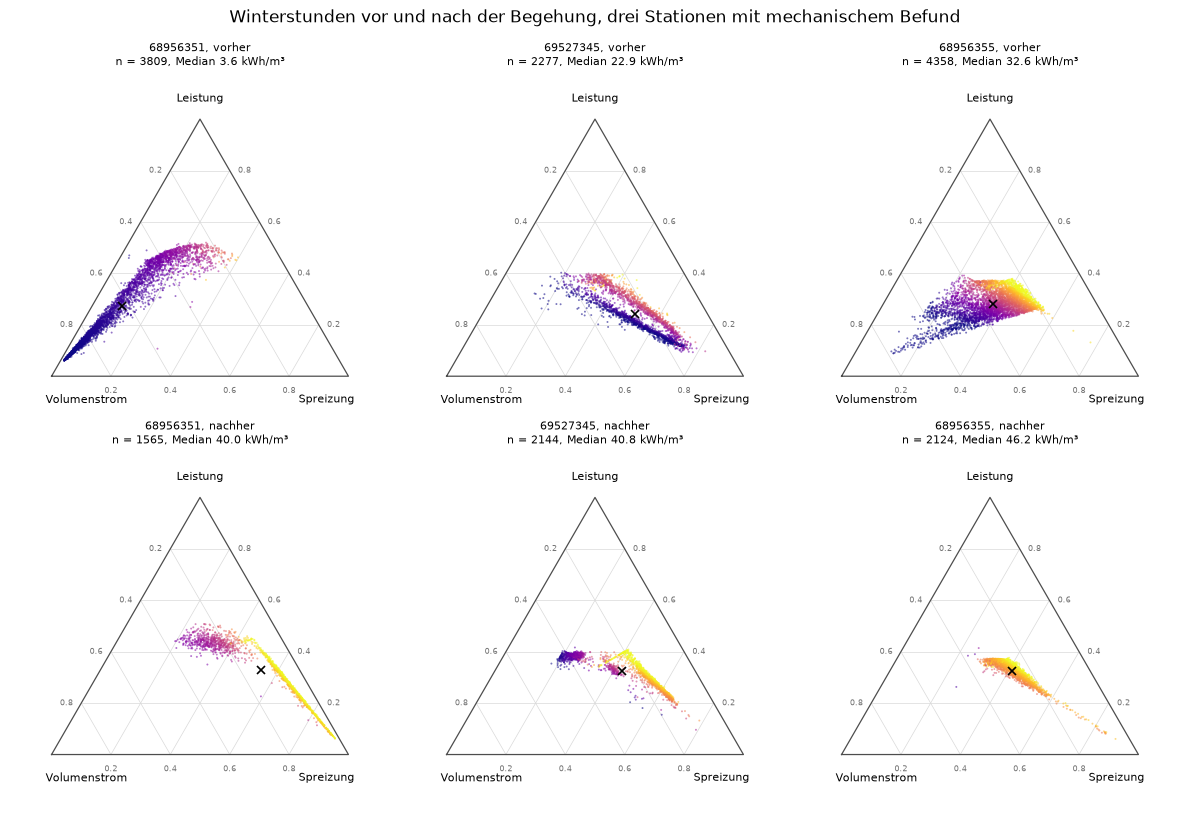

In [9]:
VORZEIGE = [68956351, 69527345, 68956355]

fig, axes = plt.subplots(2, len(VORZEIGE), figsize=(4.0 * len(VORZEIGE), 8.2))
for spalte, meter in enumerate(VORZEIGE):
    tab = tn.stationstabelle(serien[meter], meter,
                             begehungsdatum=begehungsdatum[meter])
    tab = tab[tab["gruppe_saison"] == tn.GRUPPE_WINTER]
    #gemeinsame Farbskala je Station, sonst ist vorher und nachher nicht vergleichbar
    vmin, vmax = tab["performance"].quantile([0.05, 0.95])
    for zeile, gruppe in enumerate([tn.GRUPPE_VORHER, tn.GRUPPE_NACHHER]):
        ax = axes[zeile, spalte]
        teil = tab[tab["gruppe_begehung"] == gruppe]
        tn.zeichne_panel(ax, teil, f"{meter}, {gruppe}",
                         vmin=float(vmin), vmax=float(vmax))
fig.suptitle("Winterstunden vor und nach der Begehung, drei Stationen "
             "mit mechanischem Befund", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "vorzeigefaelle_ternaer.png", dpi=120)
plt.show()

- Die Wolke rutscht jeweils von der Volumenstromecke zur Spreizungsecke und wird heller: dieselbe Wärme mit weniger Wasser
- Am deutlichsten bei 68956351, dieselbe Station mit dem Kennliniensprung in Notebook 13
- Lage im Dreieck zeigt die mittlere Aufteilung, der Modulationsanteil den Kanal der Leistungsänderung

## Stationen, die sich ohne Begehung verändert haben

- Gegenprobe, sonst sieht jede Veränderung nach Wirkung aus

In [10]:
kand = winter[~winter["begehung"] & (winter["d_perf"] > 5)].sort_values(
    "d_perf", ascending=False)
print(f"Kontrollstationen mit Steigerung ueber 5 kWh/m3: {len(kand)} von "
      f"{int((~winter['begehung']).sum())}")
print(kand[["meter", "datum", "perf_vorher", "perf_nachher", "d_perf"]]
      .round(2).to_string(index=False))
print()
mit = winter[winter["begehung"] & (winter["d_perf"] > 5)]
print(f"Begehungsstationen mit Steigerung ueber 5 kWh/m3: {len(mit)} von "
      f"{int(winter['begehung'].sum())}")

m2a = lb.meter_to_address()
adressen_mit_begehung = {m2a.get(int(m)) for m in beg_alle["meter"].dropna()}
for _, r in kand.iterrows():
    adr = m2a.get(int(r["meter"]))
    print(f"  {int(r['meter'])}: Adresse zugeordnet "
          f"{'ja' if adr else 'nein'}, Begehung an dieser Adresse "
          f"{'ja' if adr in adressen_mit_begehung else 'nein'}")

Kontrollstationen mit Steigerung ueber 5 kWh/m3: 5 von 31
   meter      datum  perf_vorher  perf_nachher  d_perf
69513891 2024-09-10        19.77         41.75   21.98
72167777 2024-10-10         5.76         26.17   20.41
80912185 2024-09-09        19.19         39.08   19.89
68956361 2024-11-06        27.45         40.94   13.49
80912158 2024-09-19        36.87         44.43    7.56

Begehungsstationen mit Steigerung ueber 5 kWh/m3: 7 von 41
  69513891: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  72167777: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  80912185: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  68956361: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  80912158: Adresse zugeordnet ja, Begehung an dieser Adresse nein


- 5 von 31 Kontrollstationen verbessern sich um mehr als 5 kWh/m³, in der Begehungsgruppe 7 von 41: ähnliche Quote
- Keine der fünf ist in der Begehungstabelle: unprotokollierte Reparatur oder geänderte Nutzung
- Eine Verbesserung allein belegt also keine Begehung

## Stationen untereinander vergleichen

- Findet die Ternärkennzahl auffällige Stationen auch ohne Begehung?

In [11]:
zeilen = []
for meter, df in sorted(serien.items()):
    tab = tn.stationstabelle(df, meter)
    if len(tab) == 0:
        continue
    w = tab[tab["gruppe_saison"] == tn.GRUPPE_WINTER]
    if len(w) < 200:
        continue
    zeile = tn.kennzahlen(w, "gruppe_saison", [tn.GRUPPE_WINTER],
                          meter=meter).iloc[0].to_dict()
    zeile["leistung_p95"] = float(w["power_kw"].quantile(0.95))
    zeile["stunden_winter"] = int(len(w))
    zeilen.append(zeile)

quer = pd.DataFrame(zeilen)
quer["begehung"] = quer["meter"].isin(set(beg_alle["meter"].dropna().astype(int)))
tick(f"Querschnitt ueber {len(quer)} Stationen mit genug Winterstunden")
print(quer[["performance_median", "anteil_mod_dt", "streuung",
            "leistung_p95"]].describe().loc[
    ["mean", "std", "min", "50%", "max"]].round(2).to_string())

[    69s] Querschnitt ueber 94 Stationen mit genug Winterstunden
      performance_median  anteil_mod_dt  streuung  leistung_p95
mean               29.64           0.20      0.12         23.75
std                10.48           0.33      0.04         66.26
min                 7.09          -0.38      0.02          3.27
50%                30.30           0.10      0.11          8.73
max                47.45           1.13      0.26        497.83


In [12]:
quer["klasse"] = pd.cut(quer["leistung_p95"], [0, 5, 10, 20, 1e9],
                        labels=["bis 5 kW", "5-10 kW", "10-20 kW",
                                "ueber 20 kW"])
print(quer.groupby("klasse", observed=True)
      .agg(stationen=("meter", "size"),
           perf_median=("performance_median", "median"),
           perf_min=("performance_median", "min"),
           perf_max=("performance_median", "max"),
           mod_dt_median=("anteil_mod_dt", "median")).round(2).to_string())
rho, p = stats.spearmanr(quer["leistung_p95"], quer["performance_median"])
print(f"\nrho(Spitzenleistung, Performance) = {rho:+.3f}, p = {p:.3g}")

             stationen  perf_median  perf_min  perf_max  mod_dt_median
klasse                                                                
bis 5 kW             9        35.59     13.84     39.54           0.02
5-10 kW             46        31.98      7.09     47.45           0.15
10-20 kW            31        31.40      7.91     45.47           0.09
ueber 20 kW          8        22.27     14.54     35.47           0.24

rho(Spitzenleistung, Performance) = -0.152, p = 0.144


- Leistungsklassen trennen die Effizienz kaum; erst über 20 kW liegt der Median niedriger, nur acht Stationen, darunter die Sonderfälle mit 498 und 201 kW
- Größe als Kontext beim Priorisieren, nicht als Clustermerkmal

In [13]:
r = fs.screening(quer)
print(f"Stationen mit Modulationsanteil ueber {fs.SCHWELLE_SPREIZUNG}: "
      f"{r['gewaehlt']} von {r['n']}")
print(f"schwaechstes Viertel liegt unter {r['grenze']:.1f} kWh/m3")
print(f"Genauigkeit {r['treffer']}/{r['gewaehlt']} = {r['genauigkeit']:.2f}, "
      f"Trefferanteil {r['treffer']}/{r['schwach']} = {r['trefferanteil']:.2f}, "
      f"Basisrate {r['basisrate']:.2f}")
print()
hoch = quer[quer["anteil_mod_dt"] > fs.SCHWELLE_SPREIZUNG]
rest = quer[quer["anteil_mod_dt"] <= fs.SCHWELLE_SPREIZUNG]
print(f"Performance spreizungsdominiert: Median "
      f"{hoch['performance_median'].median():.2f} kWh/m3 (n = {len(hoch)})")
print(f"Performance uebrige:             Median "
      f"{rest['performance_median'].median():.2f} kWh/m3 (n = {len(rest)})")
u = stats.mannwhitneyu(hoch["performance_median"], rest["performance_median"],
                       alternative="less")
d = fs.cliffs_delta(hoch["performance_median"], rest["performance_median"])
print(f"Cliffs delta {d:+.3f}   (p = {u.pvalue:.2g})")

Stationen mit Modulationsanteil ueber 0.6: 12 von 94
schwaechstes Viertel liegt unter 22.5 kWh/m3
Genauigkeit 10/12 = 0.83, Trefferanteil 10/24 = 0.42, Basisrate 0.26

Performance spreizungsdominiert: Median 14.94 kWh/m3 (n = 12)
Performance uebrige:             Median 33.09 kWh/m3 (n = 82)
Cliffs delta -0.736   (p = 2.1e-05)


- 12 von 94 Stationen regeln überwiegend über die Spreizung (Modulationsanteil über 0,6), 10 davon im schwächsten Viertel: Trefferquote 83 % bei Basisrate 26 %
- Passt zu Notebook 12: ein schlecht regelndes Ventil passt den Durchfluss nicht an, die Modulation erscheint als Spreizung. Die Kennzahl misst fehlende Regelfähigkeit

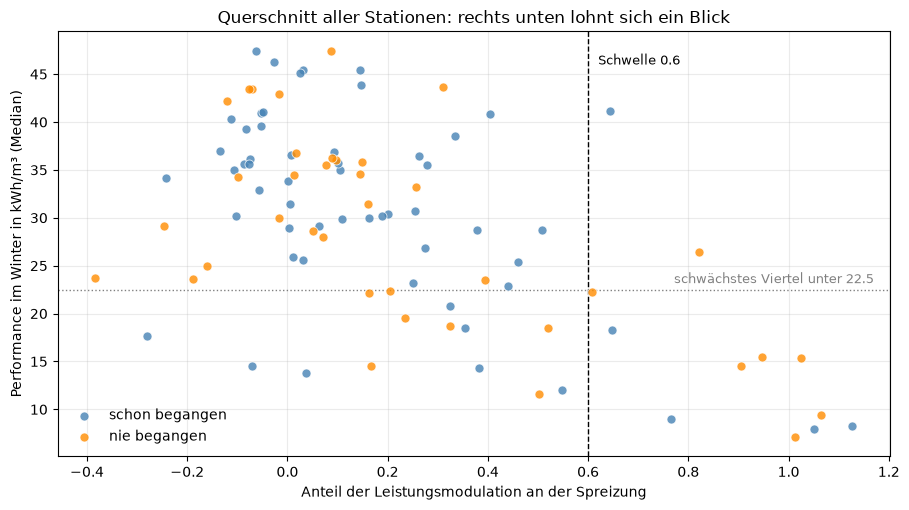

In [14]:
fig, ax = plt.subplots(figsize=(9.2, 5.2))
for maske, farbe, name in (
        (quer["begehung"], "steelblue", "schon begangen"),
        (~quer["begehung"], "darkorange", "nie begangen")):
    t = quer[maske]
    ax.scatter(t["anteil_mod_dt"], t["performance_median"], s=42,
               color=farbe, alpha=0.8, edgecolor="white", linewidth=0.6,
               label=name, zorder=3)
ax.axvline(fs.SCHWELLE_SPREIZUNG, color="black", lw=1.0, ls="--")
ax.axhline(r["grenze"], color="grey", lw=1.0, ls=":")
ax.text(fs.SCHWELLE_SPREIZUNG + 0.02, 46,
        f"Schwelle {fs.SCHWELLE_SPREIZUNG}", fontsize=9)
ax.text(1.17, r["grenze"] + 0.7,
        f"schwächstes Viertel unter {r['grenze']:.1f}", fontsize=9,
        color="grey", ha="right")
ax.set_xlabel("Anteil der Leistungsmodulation an der Spreizung")
ax.set_ylabel("Performance im Winter in kWh/m³ (Median)")
ax.set_title("Querschnitt aller Stationen: rechts unten lohnt sich ein Blick")
ax.legend(loc="lower left", frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / "querschnitt_screening.png", dpi=120)
plt.show()

In [15]:
vorschlag = quer[(quer["anteil_mod_dt"] > fs.SCHWELLE_SPREIZUNG)
                 & ~quer["begehung"]].sort_values("performance_median")
print(f"Auffaellig und noch nie begangen: {len(vorschlag)} Stationen")
print(vorschlag[["meter", "performance_median", "anteil_mod_dt", "streuung",
                 "leistung_p95", "stunden_winter"]].round(2)
      .to_string(index=False))

vorschlag.to_csv(OUT_DIR / "vorschlagsliste.csv", index=False)
winter.drop(columns=["notiz"]).to_csv(OUT_DIR / "wirkung_winter.csv",
                                      index=False)
quer.to_csv(OUT_DIR / "querschnitt_winter.csv", index=False)
tick(f"Tabellen geschrieben nach {OUT_DIR.relative_to(ROOT)}")

Auffaellig und noch nie begangen: 7 Stationen
   meter  performance_median  anteil_mod_dt  streuung  leistung_p95  stunden_winter
72135480                7.09           1.01      0.12          9.81            2616
72167793                9.42           1.07      0.18          9.41            2844
72167777               14.54           0.91      0.20         14.31            4301
81062289               15.35           1.03      0.04        185.16            2158
68956360               15.47           0.95      0.16          7.22            3904
41566330               22.21           0.61      0.05        201.41            4816
69513891               26.46           0.82      0.13         13.22            6360
[    71s] Tabellen geschrieben nach outputs\fallsammlung


- Sieben auffällige Stationen in keiner Begehungsliste (`outputs/fallsammlung/vorschlagsliste.csv`), davon haben sich 72167777 und 69513891 zusätzlich stark verändert
- Konkreteste Ausgabe des unüberwachten Strangs bisher

## Zusammenfassung & Bewertung

- Ergebnis: der saisongleiche Schnitt dreht das Ergebnis um (naiv +1,13 gegen 0,00, saisongleich −0,58 gegen +0,81), betrifft auch Notebook 12. Screening: zwölf spreizungsdominierte Stationen, zehn im schwächsten Viertel, sieben nie begangene Vorschläge
- Belastbar: der methodische Punkt und das Screening, weil reines Abzählen
- Schwach: Gruppenrangfolge (+1,98, +0,29, −0,58) nur Muster, Cliffs Delta 0,39 bei p = 0,046 und 14 gegen 27 Stationen; ein Fall mit +36 kWh/m³ trägt den Mittelwert, „mechanisch" hängt am Notierten
- Offen: was hinter den fünf Kontrollstationen mit starker Verbesserung steckt; Prüfung der Vorschlagsliste vor Ort